# Hotel Cancellation Risk Scoring: 데이터 누수(Data Leakage) 통제 기반의 예약 취소 예측

## [02_validation_models.ipynb] 목표
1. 평가 방식 확정 — 무작위 / 묶음 단위 / 시간 기준 분할 점수 비교 → 이후 모든 평가는 시간 기준으로
2. 베이스라인 재측정 — 시간 기준 분할에서 로지스틱 회귀의 "진짜" 기준점
3. 피처 정리 — 파생 피처 추가, 시간 분할에서 해가 되는 날짜 열 정리
4. 누수 재검토 — `booking_changes`, `days_in_waiting_list`, `deposit_type`, 그리고 새로 발견한 `required_car_parking_spaces`
5. 트리 계열 모델 — RandomForest, LightGBM, CatBoost 비교 → 테스트 기간에서 최종 1회 평가

1일차 함수에 더해 `time_split`, `add_features`(`src/data.py`), 트리용 전처리 `make_model(..., tree=True)`(`src/model.py`)를 쓴다.

In [1]:
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from xgboost import XGBClassifier

from src.data import (TARGET, LEAKY_COLS, POST_BOOKING_COLS, UNSTABLE_DATE_COLS, load_data,
                      arrival_date, duplicate_group_id, time_split, add_features, drop_leaky, split_xy)
from src.model import make_model, evaluate, compare

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 50)
SEED = 42

- [01.eda_baseline]에서는 무작위 분할과 중복 묶음 분할을 사용함
- 실제 호텔 현업에서는 과거 데이터로 학습해서 미래 취소를 예측해야 함
- 미래 데이터를 과거 학습에 써버리는 시간 누수를 막기위해 전체 타임라인의 시작과 끝을 먼저 확인하기
- 7~8월 여름 성수기와 겨울 비수기의 패턴이 2회 반복되는 구조로, 월별/요일별/계절별 파생 변수 설계 필요

In [2]:
# 1일차 검증 누수 제거 피처셋(X1)을 불러오고 시계열 특성 파악을 위해 도착일 컬럼을 복원
df = load_data()
X1, y = split_xy(drop_leaky(df))   # 누수 피처 3개 제외한 데이터셋
arrival = arrival_date(df)
print(f"{X1.shape[0]:,}행 × {X1.shape[1]}열, 도착일 {arrival.min():%Y-%m-%d} ~ {arrival.max():%Y-%m-%d}")

119,390행 × 28열, 도착일 2015-07-01 ~ 2017-08-31


In [3]:
# 선형 베이스라인 모델 재호출
def logreg():
    return LogisticRegression(max_iter=2000)

# 랜덤포레스트
def rf(**kw):
    return RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED, **kw)

# LightGBM
def lgbm(**kw): 
    params = dict(n_estimators=500, learning_rate=0.05, num_leaves=63, verbose=-1, random_state=SEED)
    params.update(kw)
    return LGBMClassifier(**params)

# XGBoost
def xgb(**kw): # 비교를 위해 트리 수, 학습률을 LightGBM과 맞춤
    params = dict(n_estimators=500, learning_rate=0.05, max_depth=6, tree_method="hist", n_jobs=-1, random_state=SEED)
    params.update(kw)
    return XGBClassifier(**params)

# estimator: 사용할 모델 객체 (logreg(), rf(), lgbm() 중 선택)
def fit_eval(X, estimator, train, test, tree=False): # 선형 모델은 tree=False, 트리 모델은 tree=True
    model = make_model(X, estimator, tree=tree).fit(X.loc[train], y.loc[train])
    return model, evaluate(model, X.loc[test], y.loc[test])

## 1. 평가 방식 확정

### 1-1. 월별 예약 수와 취소율
- 시간 분할을 하려면 먼저 기간별로 데이터가 어떻게 분포하는지 확인 필요

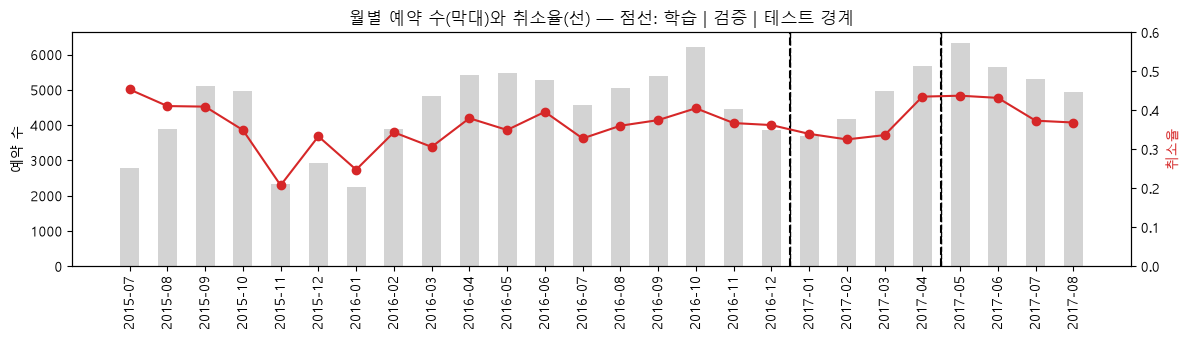

In [ ]:
month = arrival.dt.to_period("M")
monthly = df.groupby(month)[TARGET].agg(예약수="size", 취소율="mean")

x_indexes = range(len(monthly))

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(x_indexes, monthly["예약수"].values, color="lightgray", width=0.5)
ax.set_xticks(x_indexes)
ax.set_xticklabels(monthly.index.astype(str), rotation=90)
ax2 = ax.twinx()
ax2.plot(range(len(monthly)), monthly["취소율"].values, color="tab:red", marker="o")
ax2.set_ylim(0, 0.6)
ax.set_ylabel("예약 수")
ax2.set_ylabel("취소율", color="tab:red")

for period_str in ("2017-01", "2017-05"):
  x_loc = monthly.index.get_loc(pd.Period(period_str, "M"))
  ax.axvline(x_loc - 0.5, color="k", ls="--", lw=1.5)

# 월별로 그룹화
for x in (monthly.index.get_loc(pd.Period("2017-01", "M")), # 학습 데이터 70%
          monthly.index.get_loc(pd.Period("2017-05", "M"))): # 검증 데이터 15%, 테스트 데이터 15% 경계
    ax.axvline(x - 0.5, color="k", ls="--", lw=1)
ax.set_title("월별 예약 수(막대)와 취소율(선)")
ax.set_xlabel("")
plt.tight_layout()

- 2016년 가을, 2017년 봄/여름에는 예약 수가 6000건을 넘김. 반면에 연초나 특정 시기에는 3000건 아래로 떨어짐 => 뚜렷한 시계열 주기가 존재
- 월별 취소율은 보통 20~45% 사이. 2017년 4월~6월은 44% 정도로 높음
- 전체 26개월 데이터를 3구간 분할 : 세 구간의 취소율이 모두 35%~38% 선으로 일정하게 유지
    - 학습 데이터 : 2015-07 ~ 2016-12
    - 검증 데이터 : 2017-01 ~ 2017-04
    - 테스트 데이터 : 2017-05 ~ 2017-08
        - 여름 성수기가 포함되어 있음

In [6]:
train_idx, valid_idx, test_idx = time_split(df, ["2017-01-01", "2017-05-01"])
dev_idx = train_idx.append(valid_idx)   # 최종 학습용 (학습 + 검증) 인덱스

split_info = pd.DataFrame({
    "기간": ["2015-07 ~ 2016-12", "2017-01 ~ 2017-04", "2017-05 ~ 2017-08"],
    "행 수": [len(train_idx), len(valid_idx), len(test_idx)],
    "취소율": [y[i].mean() for i in (train_idx, valid_idx, test_idx)],
}, index=["학습", "검증", "테스트"]).round(3)
split_info

,기간,행 수,취소율
학습,2015-07 ~ 2016-12,78703,0.362
검증,2017-01 ~ 2017-04,18489,0.365
테스트,2017-05 ~ 2017-08,22198,0.405


- train_idx로 학습하고 valid_idx로 점수를 매겨 최적 알고리즘과 하이퍼파라미터 결정
- 하이퍼파라미터 확정 후, 테스트 세트(test_idx) 바로 직전까지의 최신 데이터(valid_idx)까지 합친 dev_idx(총 22개월 치)로 학습시킨 뒤 test_idx의 성능을 확인

### 1-2. 3가지 분할 방식 비교 (무작위, 묶음단위, 시간 기준)
- 로지스틱 회귀, 랜덤포레스트, LightGBM의 3가지 모델로 3가지 분할 전략(무작위, 묶음 단위, 시간 기준)을 교차하여 총 9번의 학습과 평가를 수행
- 시간 기준은 2017-05 이전 전체로 학습 → 테스트 기간 평가 (평가 세트 크기가 약 19%로 다른 두 방식의 20%와 비슷).

In [8]:
# 학습 세트와 평가 세트 간의 중복 행 비율 확인
rnd_train, rnd_test = train_test_split(X1.index, test_size=0.2, stratify=y, random_state=SEED)
feat_group = duplicate_group_id(X1)
g_train, g_test = next(GroupShuffleSplit(test_size=0.2, random_state=SEED).split(X1, y, groups=feat_group))
splits = {
    "무작위": (rnd_train, rnd_test),
    "묶음 단위": (X1.index[g_train], X1.index[g_test]),
    "시간 기준": (dev_idx, test_idx),
}
for name, (tr, te) in splits.items():
    seen = feat_group.loc[te].isin(set(feat_group.loc[tr])).mean()
    print(f"{name:6s}: 평가 세트 중 학습 세트에 똑같은 행이 있는 비율 {seen:.1%}")

무작위   : 평가 세트 중 학습 세트에 똑같은 행이 있는 비율 32.8%
묶음 단위 : 평가 세트 중 학습 세트에 똑같은 행이 있는 비율 0.0%
시간 기준 : 평가 세트 중 학습 세트에 똑같은 행이 있는 비율 0.0%


In [9]:
# 모델별 학습/평가
split_models = {"LogReg": (logreg, False), "RandomForest": (rf, True), "LightGBM": (lgbm, True)}
rows = {}

# 분할 방식 3종류(무작위, 묶음 단위, 시간 기준) × 모델 3종류 = 총 9개 조합에 대해 fit_eval을 실행
for s_name, (tr, te) in splits.items():
    for m_name, (est, tree) in split_models.items():
        _, score = fit_eval(X1, est(), tr, te, tree=tree)
        rows[(m_name, s_name)] = score

split_scores = pd.DataFrame(rows).T
split_scores.index.names = ["모델", "분할"]
split_scores.round(4)

,,roc_auc,pr_auc,accuracy,precision,recall,f1
모델,분할,,,,,,
LogReg,무작위,0.9084,0.8670,0.8285,0.8112,0.6999,0.7515
RandomForest,무작위,0.9595,0.9419,0.8933,0.8822,0.8216,0.8508
LightGBM,무작위,0.9564,0.9353,0.8841,0.8630,0.8168,0.8393
LogReg,묶음 단위,0.9056,0.8664,0.8202,0.7928,0.7013,0.7442
RandomForest,묶음 단위,0.9472,0.9252,0.8756,0.8558,0.8013,0.8277
LightGBM,묶음 단위,0.9494,0.9265,0.8744,0.8433,0.8147,0.8288
LogReg,시간 기준,0.8693,0.8292,0.7806,0.7139,0.7657,0.7389
RandomForest,시간 기준,0.8846,0.8413,0.7870,0.8147,0.6144,0.7005
LightGBM,시간 기준,0.8970,0.8580,0.8037,0.7931,0.6979,0.7425


분할,무작위,묶음 단위,시간 기준
모델,,,
LightGBM,0.9564,0.9494,0.8970
LogReg,0.9084,0.9056,0.8693
RandomForest,0.9595,0.9472,0.8846


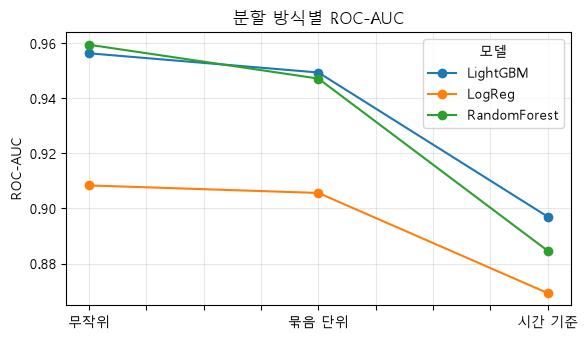

In [ ]:
# roc_auc 기준으로 분할 방식별 성능 비교 후 시각화
auc_table = split_scores["roc_auc"].unstack()[list(splits)]
display(auc_table.round(4))
auc_table.T.plot(marker="o", figsize=(6, 3.5), title="분할 방식별 ROC-AUC")
plt.ylabel("ROC-AUC"); plt.xlabel(""); plt.grid(alpha=0.3)
plt.tight_layout()

- 모든 모델에서 무작위 분할 점수가 가장 높고, 시간기준 분할 점수가 가장 낮게 나옴
    - 무작위 분할시 데이터 누수로 인해 성능이 과대평가 되었음을 확인
- 묶음 단위 분할에서의 LightGBM 성능에 비해 시간 기준 분할에서의 성능이 대폭 하락함
    - 시간의 흐름에 따라 데이터 분포가 변하고, 묶음 분할은 시계열적 변화를 반영하지 못한다는 것을 확인
- 시간 기준 분할에서 LightGBM이 ROC-AUC 0.8970 기록
    - 로지스틱 회귀 대비 약 0.028 높고, F1-score 에서도 우위
=> 실제 호텔 운영 환경과 동일한 '시간 기준 분할'과 LightGBM을 최종 베이스라인으로 채택하여 피처 엔지니어링 적용할 예정

## 2. 베이스라인 재확인
- 로지스틱 회귀를 시간 기준 분할로 다시 측정


In [ ]:
dummy, dummy_score = fit_eval(X1, DummyClassifier(strategy="most_frequent"), dev_idx, test_idx)
base_lr, base_score = fit_eval(X1, logreg(), dev_idx, test_idx)
baseline = compare({
    "Dummy(다수 클래스)": dummy_score,
    "LogReg 무작위 분할": split_scores.loc[("LogReg", "무작위")].to_dict(),
    "LogReg 시간 기준 분할": base_score,
})
baseline

,roc_auc,pr_auc,accuracy,precision,recall,f1
Dummy(다수 클래스),0.5000,0.4055,0.5945,0.0000,0.0000,0.0000
LogReg 무작위 분할,0.9084,0.8670,0.8285,0.8112,0.6999,0.7515
LogReg 시간 기준,0.8693,0.8292,0.7806,0.7139,0.7657,0.7389


- 무작위 분할의 0.9084는 과대평가 값이었던 것으로 확인
- 시간 기준 분할 진짜 기준점은 ROC-AUC 0.8693 / PR-AUC 0.8292
- 호텔의 예약 데이터는 취소가 상대적으로 적은 클래스 불균형이 있기 때문에 PR-AUC도 확인

## 3. 피처 엔지니어링
- 새로운 파생 변수 추가하면 train_idx(2015-07 ~ 2016-12)로 학습시키고 valid_idx(2017-01 ~ 2017-04)로만 평가하여 해당 피처를 채택할지 안할지 결정
- 선형/트리 모델에서 효과가 다를 수 있으므로 로지스틱 회귀와 LightGBM 두 모델을 비교

In [12]:
# 새로운 피처셋(X)을 만들 때마다, 선형 모델(LogReg)과 트리 모델(LightGBM)에 각각 넣어서 점수가 얼마나 변하는지 한 번에 채점
def valid_scores(X, label):
    out = {}
    for m_name, (est, tree) in {"LogReg": (logreg, False), "LightGBM": (lgbm, True)}.items():
        _, s = fit_eval(X, est(), train_idx, valid_idx, tree=tree)
        out[(m_name, "roc_auc")], out[(m_name, "pr_auc")] = s["roc_auc"], s["pr_auc"]
    return pd.Series(out, name=label)

### 3-1. 파생 피처 추가 (`add_features`)

| 피처 | 정의 |
|---|---|
| `total_nights` | 주말 + 주중 숙박일 |
| `total_guests`, `has_kids` | 성인+어린이+유아 / 어린이·유아 동반 여부 |
| `arrival_weekday` | 도착 요일 |
| `via_agent`, `via_company` | 대리점 / 회사 경유 여부 (ID 결측 여부) |
| `adr_per_person` | 1인당 1박 요금 |
| `prev_cancel_ratio` | 과거 예약 중 취소 비율 (과거 예약 없으면 0) |

- total_nights (주말 + 주중 숙박일)
    - stays_in_weekend_nights와 stays_in_week_nights를 합산.
    - 가설 : 1박짜리 초단기 투숙인지, 7박 이상의 장기 여행인지에 따라 취소 패턴이 갈릴 것이다.
- total_guests, has_kids (총 인원 / 아이 동반 여부)
    - 가설 : 아이를 동반한 가족 여행은 일정 변경이 어렵기 때문에 단독 여행객보다 취소율이 낮을 것이다.   
- arrival_weekday (도착 요일)
    - 가설 : 금,토 체크인은 주말 레저/휴가 목적, 일,월 체크인은 비즈니스 출장일 가능성이 높을 것이다. 여행 목적이 다르면 취소 성향도 다를 것이다.
- via_agent, via_company (대리점/기업 경유 여부)   
    - 가설1 : 비싼 방을 여행사를 거쳐 예약했을 경우 취소율이 높을 것이다.
    - 가설2 : 기업 경유 예약은 가격이 올라도 취소율 변화가 미미할 것이다. (돈을 내는 사람과 숙박하는 사람이 다를 수 있음) 
- adr_per_person (1인당 1박 요금)   
    - 가설 : 1인당 요금이 높을수록 취소율이 높을 것이다.
    - 반대가설 : 비싼 방을 예약한 고객은 여행 의지가 확실해서 예약을 덜 취소할 것이다.
- prev_cancel_ratio (과거 예약 중 취소 비율)   
    - 가설 : 과거 자주 취소했던 고객은 취소할 확률이 높을 것이다.

### 3-2. 날짜 열 정리
- 도착 날짜 열 관련 두개를 빼고 검증 점수가 어떻게 바뀌는지 확인 후 뺄지 말지를 결정하기
    - `arrival_date_year`: 학습 데이터는 2015~2016년이고 검증 데이터는 전부 2017년이다. 평가 기간의 연도가 학습 때 처음 보는 값이라 패턴을 일반화하기 어렵다.
    - `arrival_date_week_number`: 같은 10주차라도 해마다 날짜, 요일이 달라 트리가 "2016년 특정 주"를 외울 위험이 있다. 계절성은 `arrival_date_month`로 충분하다.

- ① 기본 피처셋 : 원본 컬럼에서 누수열 3개만 뺀 피처들
- ② 기본 + 파생피처 : 기본 피처셋에 파생 피처를 더함
- ③ 기본+파생(연도제외) : arrival_date_year 제거
- ④ 기본+파생(연도/주차 제외) : arrival_date_year, arrival_date_week_number 제거

In [1]:
X1F = split_xy(drop_leaky(add_features(df)))[0]   # 기본+파생 피처

feature_steps = pd.concat([
    valid_scores(X1, "① 기본 피처셋"),
    valid_scores(X1F, "② 기본+파생 피처"),
    valid_scores(X1F.drop(columns="arrival_date_year"), "③ 기본+파생(연도제외)"),
    valid_scores(X1F.drop(columns=UNSTABLE_DATE_COLS), "④ 기본+파생(연도/주차 제외)"),
], axis=1).T
feature_steps.round(4)

NameError: name 'split_xy' is not defined

- 파생 피처의 효과가 미미하다.
- 주차 열 제거는 LightGBM에서 ROC-AUC +0.011로 가장 큰 개선을 보인다. 트리가 특정 주차를 외우고 있었다. 선형 모델은 차이 없음.
    - → `UNSTABLE_DATE_COLS = ["arrival_date_year", "arrival_date_week_number"]` 제거 확정.

## 4. 누수 재확인
- 누수를 결정하는 기준은 손님이 예약을 완료한 순간 바로 그 시점에 정해지는 값인가?를 보고 판단한다.
- 01_eda_baseline에서 판단을 보류했던 열
    - booking_changes, days_in_waiting_list, deposit_type, country
- 새로 의심되는 열
    - required_car_parking_spaces

In [ ]:
# 열 값 별로 예약 수와 취소율을 집계하고, 3 이상은 3으로 묶어서 시각화하여 어떤 값에서 취소율이 극단적인가를 본다
def rate_by(col, clip=3):
    s = df[col].clip(upper=clip) if pd.api.types.is_numeric_dtype(df[col]) else df[col]
    return df.groupby(s)[TARGET].agg(예약수="size", 취소율="mean").round(3)

for col in ["required_car_parking_spaces", "booking_changes", "days_in_waiting_list"]:
    print(f"[{col}] (3 이상은 3으로 묶음)")
    display(rate_by(col))

[required_car_parking_spaces] (3 이상은 3으로 묶음)


,예약수,취소율
required_car_parking_spaces,,
0,111974,0.395
1,7383,0.000
2,28,0.000
3,5,0.000


[booking_changes] (3 이상은 3으로 묶음)


,예약수,취소율
booking_changes,,
0,101314,0.409
1,12701,0.142
2,3805,0.201
3,1570,0.166


[days_in_waiting_list] (3 이상은 3으로 묶음)


,예약수,취소율
days_in_waiting_list,,
0,115692,0.362
1,12,0.250
2,5,0.200
3,3681,0.640


- required_car_parking_spaces : 주차 공간을 1대 이상 요청한 고객은 취소율이 0%로 누수로 보임.
- booking_changes : 예약 변경 0회(약 40%)와 1회 이상의 차이가 큰 편이다. 누수인지 아닌지 알기 어려움
    - 일정을 변경하는 고객은 여행 의지가 있어서 덜 취소한다.
    - 취소된 예약은 변경이 더 쌓이지 않으므로 0회에 몰린다.
- days_in_waiting_list : 취소율이 극단적이지 않고, 대기가 길수록 취소가 많다는 것은 자연스럽다. 누수로 보기 어려움.

### 4-1. `required_car_parking_spaces` 누수 확인

In [13]:
pd.crosstab(df["required_car_parking_spaces"] > 0, df[TARGET].map({0: "유지", 1: "취소"}),
            rownames=["주차 요청 있음"], colnames=[None], margins=True)

,유지,취소,All
주차 요청 있음,,,
False,67750,44224,111974
True,7416,0,7416
All,75166,44224,119390


- 주차 공간을 요청한 예약 7416건 중 취소가 0건. 우연으로 보기 힘들고 실제로 도착해서 주차한 경우라고 보는 것이 자연스럽다. 이는 곧 체크인했다는 힌트이므로 누수로 판정하여 제거한다.

### 4-4. `deposit_type = Non Refund` — 취소율 99%의 정체

In [14]:
nr = df["deposit_type"].eq("Non Refund")
nr_profile = pd.DataFrame({
    "Non Refund": [nr.sum(), df.loc[nr, TARGET].mean(), df.loc[nr].duplicated(keep=False).mean(),
                   df.loc[nr, "hotel"].eq("City Hotel").mean(), df.loc[nr, "country"].eq("PRT").mean(),
                   df.loc[nr, "market_segment"].isin(["Groups", "Offline TA/TO"]).mean()],
    "그 외": [(~nr).sum(), df.loc[~nr, TARGET].mean(), df.loc[~nr].duplicated(keep=False).mean(),
             df.loc[~nr, "hotel"].eq("City Hotel").mean(), df.loc[~nr, "country"].eq("PRT").mean(),
             df.loc[~nr, "market_segment"].isin(["Groups", "Offline TA/TO"]).mean()],
}, index=["예약 수", "취소율", "중복 행 비율", "City Hotel 비율", "포르투갈(PRT) 비율", "단체·오프라인 여행사 비율"])
nr_profile.round(3)

,Non Refund,그 외
예약 수,14587.000,104803.000
취소율,0.994,0.284
중복 행 비율,0.981,0.247
City Hotel 비율,0.882,0.634
포르투갈(PRT) 비율,0.972,0.328
단체·오프라인 여행사 비율,0.972,0.285


- 환불 불가인데 취소율 99%인 것은 개인 고객 행동으로 보기 어려움.
- Non Refund 예약은 98%가 중복 행, 97%가 포르투갈, 대부분 단체·오프라인 여행사, 88%가 City Hotel이다.
- 여행사의 대량 선점 -> 일괄 취소 패턴이 몰려있다.
- 보증금 조건 자체는 예약 시점에 정해지는 값이므로 누수는 아니라서 유지한다. 

### 4-5. `country` — 참고: 기본값 PRT 의심

In [15]:
print("취소된 예약 중 PRT 비율:", round(df.loc[df[TARGET] == 1, "country"].eq("PRT").mean(), 3))
print("유지된 예약 중 PRT 비율:", round(df.loc[df[TARGET] == 0, "country"].eq("PRT").mean(), 3))

취소된 예약 중 PRT 비율: 0.622


유지된 예약 중 PRT 비율: 0.28


- 취소된 예약의 62%가 PRT(내수고객)인 반면, 유지된 예약은 28%만 PRT다. 
- 포르투갈 내 거주자는 호텔까지 비행기를 탈 필요가 없고, 현지 대체 숙소가 많기 때문에 일정 변경과 취소에 대한 부담이 외국인보다 낮다.
- 앞서 분석한 Non Refund(환불 불가인데 취소율 99%) 집단에서 포르투갈 비율이 95% 이상이었는데, 포르투갈 현지 여행사들의 예약 일괄 취소 패턴이 전체 취소 데이터의 국적 통계도 왜곡시키고 있을 수 있다.
- 모델에서 country_PRT는 취소를 강력하게 밀어올리는 중요피처로 작동할 수 있다.
    - 다만, 포르투갈 사람이기 때문에 취소한다는 것보다는 현지 내수 단체 예약의 일괄 취소 관행이 대량으로 섞인 데이터임을 인지할 필요가 있다.

### 4-6. 제거 시 성능 영향 (검증 기간)

In [ ]:
X_base = X1F.drop(columns=UNSTABLE_DATE_COLS)   # 3장까지 정리한 피처
leak_review = pd.concat([
    valid_scores(X_base, "① 기준:날짜 정리완료 피처"),
    valid_scores(X_base.drop(columns="required_car_parking_spaces"), "② 주차 요청 열 제거"),
    valid_scores(X_base.drop(columns=POST_BOOKING_COLS), "③ 주차요청/예약변경횟수 열 제거(최종)"),
    valid_scores(X_base.drop(columns=POST_BOOKING_COLS + ["deposit_type"]), "(의존도확인)최종+보증금유형제거"),
    valid_scores(X_base.drop(columns=POST_BOOKING_COLS + ["country"]), "(의존도확인)최종+국가제거"),
], axis=1).T
leak_review.round(4)

LogReg         LightGBM        
                 roc_auc  pr_auc  roc_auc  pr_auc
③장까지 정리한 피처       0.8856  0.8391   0.9068  0.8628
− 주차              0.8745  0.8305   0.9009  0.8576
− 주차 − 변경횟수 (확정)  0.8719  0.8264   0.8973  0.8533
(참고) 확정 − 보증금     0.8602  0.8032   0.8900  0.8297
(참고) 확정 − 국가      0.8428  0.8110   0.8622  0.8223

- 주차/예약변경횟수를 빼면 ROC-AUC가 LightGBM은 약 0.01, 로지스틱 회귀는 약 0.014 내려간다.
- `deposit_type`, `country`는 빼면 각각 크게 떨어진다. 모델이 이 두 열에 많이 기대고 있는 것 같아서 나중에 비중을 확인해야 함.

**누수 점검 최종 판정**

| 열 | 판정 | 발견 방법 | 근거 |
|---|---|---|---|
| `reservation_status`, `reservation_status_date`, `assigned_room_type` | 제거 | 단일 열 AUC | 예약 결과·체크인 이후에 기록되는 값 |
| `required_car_parking_spaces` | **제거** | 값별 취소율 | 주차 요청 7,416건 중 취소 0건 → 도착 후 기록되는 값으로 추정 |
| `booking_changes` | **제거** | 기록 시점 추론 | 데이터 추출 시점까지 누적된 최종값. 취소 후에는 변경이 더 쌓이지 않음 |
| `days_in_waiting_list` | 유지 | 값별 취소율 + 기록 시점 | 예약 확정 전에 정해지는 값, 극단적 패턴 없음 |
| `deposit_type` | 유지 (한계 기록) | 집단 프로필 비교 | 예약 시점에 정해지는 값. Non Refund 99% 취소는 여행사 단체 일괄 취소 패턴 |
| `country` | 유지 (한계 기록) | 기록 시점 추론 | 정정되지 않은 기본값 PRT가 섞였을 가능성 (데이터로 검증 불가) |

## 5. 트리 계열 모델 비교 (검증 기간)
- 누수와 불안정한 열을 모두 빼고 최종 피처로 여러 모델을 경쟁시켜 최종 모델을 고르는 단계
- 최종 피처: 기본 피처셋(28개) + 파생 피처(9개) − 연도/주차 제거(2개) − 주차 요청/예약 변경횟수 제거(2개)
- 트리 모델은 표준화 없이 City Hotel -> 0, Resort Hotel -> 1 로 정수변환
- 부스팅 계열은 LightGBM, XGBoost, CatBoost 세 가지를 비교한다.
- 하이퍼파라미터는 몇 가지 대표 값만 검증 기간에서 비교한다(과한 튜닝은 검증 기간에 과적합).

In [17]:
X = X_base.drop(columns=POST_BOOKING_COLS)   # 최종 피처
print(f"최종 피처 {X.shape[1]}개:", list(X.columns))

최종 피처 32개: ['hotel', 'lead_time', 'arrival_date_month', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'total_of_special_requests', 'total_nights', 'total_guests', 'has_kids', 'arrival_weekday', 'via_agent', 'via_company', 'adr_per_person', 'prev_cancel_ratio']


In [18]:
candidates = {
    "LogReg": (logreg(), False),
    "RandomForest": (rf(), True),
    "RandomForest (min_samples_leaf=5)": (rf(min_samples_leaf=5), True),
    "LightGBM (num_leaves=63)": (lgbm(), True),
    "LightGBM (num_leaves=31)": (lgbm(num_leaves=31), True),
    "LightGBM (num_leaves=127)": (lgbm(num_leaves=127), True),
    "LightGBM (31, subsample 0.8)": (lgbm(num_leaves=31, subsample=0.8, subsample_freq=1, colsample_bytree=0.8), True),
    "XGBoost (max_depth=6)": (xgb(), True),
    "XGBoost (max_depth=4)": (xgb(max_depth=4), True),
    "CatBoost (depth=6)": (CatBoostClassifier(iterations=1000, learning_rate=0.05, depth=6,
                                              verbose=0, random_seed=SEED, allow_writing_files=False), True),
}
valid_rows, fit_secs = {}, {}
for name, (est, tree) in candidates.items():
    t = time.perf_counter()
    _, valid_rows[name] = fit_eval(X, est, train_idx, valid_idx, tree=tree)
    fit_secs[name] = time.perf_counter() - t

model_compare = compare(valid_rows).assign(학습시간_초=pd.Series(fit_secs).round(1))
model_compare.sort_values("roc_auc", ascending=False)

,roc_auc,pr_auc,accuracy,precision,recall,f1,학습시간_초
"LightGBM (31, subsample 0.8)",0.9018,0.8571,0.8158,0.8175,0.6372,0.7162,1.9
CatBoost (depth=6),0.9015,0.8553,0.8125,0.8175,0.6257,0.7089,12.0
LightGBM (num_leaves=31),0.9011,0.8564,0.8143,0.8120,0.6386,0.7150,1.8
XGBoost (max_depth=6),0.9007,0.8558,0.8141,0.8184,0.6300,0.7120,2.4
XGBoost (max_depth=4),0.8993,0.8523,0.8095,0.8209,0.6109,0.7005,2.0
LightGBM (num_leaves=63),0.8973,0.8533,0.8138,0.8067,0.6437,0.7160,2.3
LightGBM (num_leaves=127),0.8941,0.8491,0.8120,0.8094,0.6339,0.7110,3.5
RandomForest (min_samples_leaf=5),0.8884,0.8398,0.8047,0.8251,0.5897,0.6878,4.1
RandomForest,0.8849,0.8361,0.8069,0.8241,0.5982,0.6932,4.5
LogReg,0.8719,0.8264,0.7923,0.8415,0.5305,0.6508,1.9


이 코드는 누수가 완전히 제거된 최종 피처셋 X 위에서 선형 베이스라인(LogReg), 배깅(RandomForest 규제 여부), 부스팅(LightGBM 트리 복잡도/샘플링 변형), 그리고 범주형에 강한 CatBoost까지 총 8종의 모델 후보군을 시간 기준 검증 세트(valid_idx)에 올려놓고 성능과 학습 속도를 맞비교하는 종합 토너먼트 실험

- 부스팅 계열(LightGBM, XGBoost, CatBoost)이 RandomForest·로지스틱 회귀보다 확실히 낫다.
- LightGBM(`num_leaves=31`)·LightGBM(subsample)·CatBoost가 ROC-AUC 0.901~0.902로 사실상 동률이다. subsample(행 샘플링) 추가 이득(+0.0007)은 잡음 수준이라 더 단순한 설정을 고르고, CatBoost보다 학습이 약 6배 빠른 LightGBM을 택한다.
- XGBoost(`max_depth=6`)도 0.9007로 같은 수준이다. 부스팅 세 가지가 0.900~0.902 안에 모여 있어 **알고리즘보다 피처·평가 방식이 성능을 좌우한다**고 볼 수 있다. 셋이 사실상 동률이므로 빠르고 단순한 LightGBM을 유지한다.
- 잎 수를 늘리면(63 → 127) 오히려 떨어진다 → 복잡도는 31 정도면 충분.
- **최종 모델: LightGBM (`num_leaves=31`, `n_estimators=500`, `learning_rate=0.05`)**. 비교 대상으로 로지스틱 회귀(최종 피처)와 RandomForest도 테스트에서 함께 본다.

ubsample이 원래 하는 역할
원리: 트리를 하나 만들 때마다 학습 데이터 전체(100%)를 다 쓰는 게 아니라, 무작위로 일부(예: 80%)만 뽑아서 학습시키는 방식입니다.

목적: 모든 트리가 똑같은 데이터 패턴에 얽매이지 않게 강제로 다양성을 주어, 과적합(Overfitting)을 방지하는 규제(Regularization) 기법입니다.

오컴의 면도날 (더 단순한 설정 선택):

머신러닝 실무에서는 "성능 차이가 거의 없다면(잡음 수준이라면), 하이퍼파라미터가 덜 붙은 더 단순한 모델을 고른다"는 철칙이 있습니다.

굳이 subsample=0.8, colsample_bytree=0.8 같은 복잡한 옵션을 달고 가봤자 실질적인 이득이 없으니, 가장 기본적이고 단순한 num_leaves=31 단독 모델을 최종 채택한 것입니다.

## 6. 테스트 기간 최종 평가 (1회)

선택이 모두 끝났으므로 학습+검증(2015-07 ~ 2017-04)으로 다시 학습하고 테스트(2017-05 ~ 2017-08)에서 평가한다.

In [19]:
final_specs = {
    "LogReg (최종 피처)": (X, logreg(), False),
    "RandomForest (최종 피처)": (X, rf(min_samples_leaf=5), True),
    "LightGBM (최종 피처)": (X, lgbm(num_leaves=31), True),
    "XGBoost (최종 피처)": (X, xgb(), True),
}
final_models, final_rows = {}, {}
for name, (Xs, est, tree) in final_specs.items():
    final_models[name], final_rows[name] = fit_eval(Xs, est, dev_idx, test_idx, tree=tree)

test_results = compare({
    "Dummy(다수 클래스)": dummy_score,
    "1일차 LogReg (기준점)": base_score,
    "(참고) LightGBM 1일차 피처": split_scores.loc[("LightGBM", "시간 기준")].to_dict(),
    **final_rows,
})
test_results

,roc_auc,pr_auc,accuracy,precision,recall,f1
Dummy(다수 클래스),0.5000,0.4055,0.5945,0.0000,0.0000,0.0000
1일차 LogReg (기준점),0.8693,0.8292,0.7806,0.7139,0.7657,0.7389
(참고) LightGBM 1일차 피처,0.8970,0.8580,0.8037,0.7931,0.6979,0.7425
LogReg (최종 피처),0.8474,0.8101,0.7585,0.7910,0.5496,0.6486
RandomForest (최종 피처),0.8545,0.8128,0.7670,0.8127,0.5528,0.6580
LightGBM (최종 피처),0.8704,0.8278,0.7758,0.8066,0.5880,0.6802
XGBoost (최종 피처),0.8691,0.8253,0.7688,0.7974,0.5763,0.6690


- 검증세트(valid_idx)포함한 전체 데이터(dev_idx)로 다시학습함 
- test_results는 최종점수 띨롱이 아니라 베이스라인부터 최종 모델까지 단계별 서사 보여줌
dummy = 바닥(최소기준선)
바닥 (Floor)	Dummy(다수 클래스)	머신러닝 없이 단순 다수결로 찍었을 때의 점수 (최소 기준선)
시작점	1일차 LogReg (기준점)	누수만 겨우 빼고 아무것도 건드리지 않았던 프로젝트 Day 1의 초기 점수
기술적 대조군	(참고) LightGBM 1일차 피처	피처 엔지니어링이나 정제 없이 단순히 좋은 알고리즘만 썼을 때의 점수
최종 후보 1	LogReg (최종 피처)	피처 엔지니어링과 정제 작업을 거쳤을 때 선형 모델의 한계치
최종 후보 2	RandomForest (최종 피처)	배깅 앙상블의 최종 성적표
최종 주인공	LightGBM (최종 피처)	모든 최적화가 집약된 최종 챔피언 모델의 실전 성적

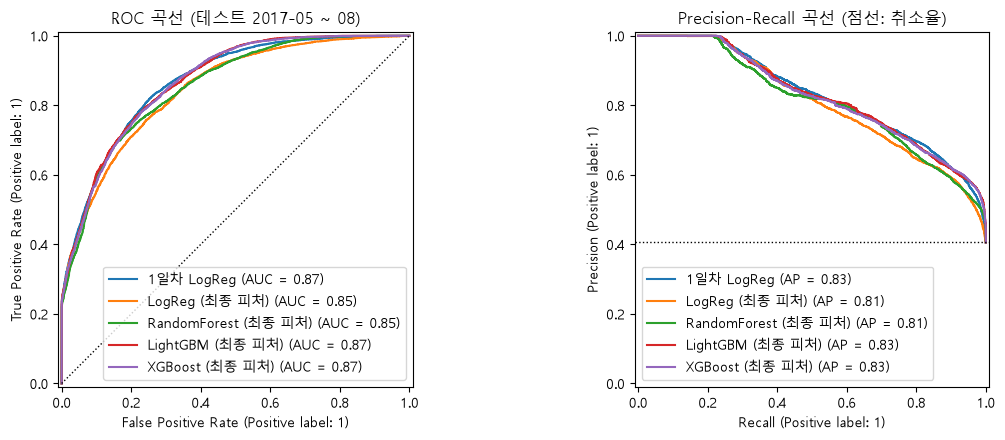

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
X_test, y_test = X.loc[test_idx], y.loc[test_idx]
RocCurveDisplay.from_estimator(base_lr, X1.loc[test_idx], y_test, ax=axes[0], name="1일차 LogReg")
PrecisionRecallDisplay.from_estimator(base_lr, X1.loc[test_idx], y_test, ax=axes[1], name="1일차 LogReg")
for name, model in final_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[0], name=name)
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, ax=axes[1], name=name)
axes[0].plot([0, 1], [0, 1], "k:", lw=1)
axes[0].set_title("ROC 곡선 (테스트 2017-05 ~ 08)")
axes[1].axhline(y_test.mean(), color="k", ls=":", lw=1)
axes[1].set_title("Precision-Recall 곡선 (점선: 취소율)")
plt.tight_layout()

- 좌측 ㅣ 대각선 45도 점선은 "동전 던지기(랜덤 찍기)" 수준의 무작위 예측 기준선(AUC = 0.5)입니다. 곡선이 좌상단(0, 1) 모서리에 바짝 붙을수록 뛰어난 모델입니다.
- 우측  | 곡선이 우상단(1, 1) 쪽에 높게 유지될수록 불균형 데이터셋에서 알짜배기 성능을 낸다

둘 다 똑같은 로지스틱 회귀 모델이지만, 곡선이 위로 붕 뜨는 모습을 통해 "누수 제거와 파생 피처 엔지니어링만으로 알고리즘 변경 없이 선형 모델의 성능 한계를 얼마나 끌어올렸는가"를 시각적으로 보여줍니다.

RandomForest vs LightGBM:

트리 계열 중에서도 배깅(RF) 대비 부스팅(LightGBM)이 시계열 테스트 구간에서 곡선을 훨씬 높은 고도로 유지하는 모습을 증명합니다.

실무적 의사결정 구간 확인 (우측 PR 곡선):

호텔 비즈니스에서 "과도한 오버부킹이나 프로모션 비용"을 통제하려면 Precision이 80% 이상으로 유지되는 구간을 찾아야 합니다.

LightGBM 곡선이 높은 Precision을 유지하면서 Recall을 어디까지 끌고 갈 수 있는지, 즉 실제 운영 시 사용할 최적의 확률 임계값(Threshold)을 결정하는 결정적 근거 자료가 됩니다.

In [21]:
# 테스트 기간 월별로 성능이 고르게 나오는지 확인
lgb_final = final_models["LightGBM (최종 피처)"]
by_month = {}
for m, idx in X_test.groupby(arrival.loc[test_idx].dt.to_period("M")).groups.items():
    by_month[str(m)] = {"예약수": len(idx), "취소율": y.loc[idx].mean(),
                        **evaluate(lgb_final, X.loc[idx], y.loc[idx])}
pd.DataFrame(by_month).T[["예약수", "취소율", "roc_auc", "pr_auc", "f1"]].astype(float).round(3)

,예약수,취소율,roc_auc,pr_auc,f1
2017-05,6313.0,0.438,0.908,0.893,0.760
2017-06,5647.0,0.432,0.882,0.865,0.727
2017-07,5313.0,0.373,0.835,0.738,0.583
2017-08,4925.0,0.369,0.833,0.726,0.590


**결과 해석 — 숫자를 있는 그대로 읽기**
- **최종 LightGBM(0.870)은 기준점(0.869)과 ROC-AUC가 사실상 같다.** "모델을 바꿔서 크게 좋아졌다"는 결과는 아니다.
- 다만 두 점수는 같은 조건이 아니다. 기준점은 누수로 판단한 주차·변경횟수 열을 쓰고 있다.
  **같은 정직한 피처끼리 비교하면** LogReg 0.847 → RandomForest 0.855 → **LightGBM 0.870 (+0.023)** 으로 트리 부스팅의 이득이 분명하다.
  XGBoost(최종 피처)도 0.869로 LightGBM과 같은 수준이다. 검증 기간의 동률이 테스트에서도 그대로 이어져, 부스팅 모델 중 무엇을 골랐는지는 결과에 거의 영향이 없다.
- (참고) 1일차 피처 그대로의 LightGBM은 0.897이다. 0.897 → 0.870의 차이는 누수 의심 열·날짜 열 제거의 대가인데,
  이 결정들은 검증 기간 근거로 내렸으므로 **테스트 점수를 보고 되돌리지 않는다**(테스트를 보고 고르면 테스트도 부풀려진다).
- **미래로 갈수록 성능이 떨어진다.** 검증 기간 0.901 → 테스트 0.870이고, 월별로 보면 5월 0.908 → 6월 0.882 → 7~8월 0.83.
  학습 끝 시점에서 멀어질수록 패턴이 바뀐다는 뜻이므로, 실제 운영이라면 **매달 재학습**이 필요하다.
  -이 모델의 신뢰 반감기(Half-life)는 최대 1~2개월이므로, 현업 배치 파이프라인은 최소 월간(Monthly) 단위로 재학습(Retraining) 주기를 설정해야 한다"는 구체적인 엔지니어링 액션 아이템을 도출했습니다.
- **F1은 기준점보다 낮다(0.739 → 0.680).** threshold 0.5에서 LightGBM의 Recall이 0.59로 낮기 때문이다.
  테스트 기간 취소율(40.5%)이 학습 기간(36%)보다 높아 0.5가 너무 보수적인 기준이 된 것으로, 순위 지표(ROC/PR-AUC)와 달리 threshold에 좌우되는 지표다 → 3일차에 비용 기준으로 threshold를 정한다.

코드에서 명시적으로 threshold = 0.5라고 적은 적은 없지만, 우리가 모르는 사이에 Scikit-learn이 기본값으로 0.5를 강제 적용하고 있었습니다.

이게 무슨 말인지 3단계로 쉽게 풀어보면 이렇습니다.

1. predict() 함수가 몰래 저지른 일
우리가 모델을 평가할 때 보통 내부적으로 두 가지 메서드를 씁니다.

predict_proba(X): 모델이 계산한 연속적인 취소 확률을 줍니다. (예: "이 손님은 취소할 확률이 0.48입니다.")

ROC-AUC나 PR-AUC는 이 '확률값 자체'의 줄 세우기(순위)를 보고 계산하므로 아무런 임계값이 필요 없습니다.

predict(X): 모델이 딱 잘라서 0(투숙)인지 1(취소)인지 줍니다.

Scikit-learn의 모든 분류기는 predict(X)를 부르면 "확률이 0.5를 넘으면 1(취소), 0.5 미만이면 0(투숙)"으로 자르도록 하드코딩되어 있습니다.

즉, F1-score를 계산할 때 쓰인 예측값(0과 1)에 이미 보이지 않게 0.5라는 임계값이 박혀 있었던 것입니다.

## 7. 2일차 정리

In [22]:
print("평가 방식: 도착일 기준 시간 분할 (학습 ~2016-12 / 검증 2017-01~04 / 테스트 2017-05~08)")
print(f"추가 제거 열: 누수 의심 {POST_BOOKING_COLS}, 불안정 날짜 {UNSTABLE_DATE_COLS}")
for name in ["1일차 LogReg (기준점)", "LogReg (최종 피처)", "LightGBM (최종 피처)", "XGBoost (최종 피처)"]:
    s = test_results.loc[name]
    print(f"{name:20s}: ROC-AUC {s.roc_auc:.3f} / PR-AUC {s.pr_auc:.3f} / F1 {s.f1:.3f}")

평가 방식: 도착일 기준 시간 분할 (학습 ~2016-12 / 검증 2017-01~04 / 테스트 2017-05~08)
추가 제거 열: 누수 의심 ['required_car_parking_spaces', 'booking_changes'], 불안정 날짜 ['arrival_date_year', 'arrival_date_week_number']
1일차 LogReg (기준점)    : ROC-AUC 0.869 / PR-AUC 0.829 / F1 0.739
LogReg (최종 피처)      : ROC-AUC 0.847 / PR-AUC 0.810 / F1 0.649
LightGBM (최종 피처)    : ROC-AUC 0.870 / PR-AUC 0.828 / F1 0.680
XGBoost (최종 피처)     : ROC-AUC 0.869 / PR-AUC 0.825 / F1 0.669


**3일차 할 일**
- 최종 LightGBM 해석: 피처 중요도, SHAP — 특히 `deposit_type`, `country`, `lead_time` 의존도 확인
- threshold 조정: 취소를 놓치는 비용 vs 멀쩡한 예약을 취소로 보는 비용 → 초과 예약·확인 연락 시나리오
- 한계 정리: Non Refund 일괄 취소 패턴, `country` 기본값 의심, 시간이 지날수록 성능 저하(재학습 주기)